# SAM vs SGD at matched training loss: Fashion-MNIST demo

**Question.** Does sharpness-aware minimisation (SAM) improve test accuracy and calibration over plain SGD for a small convolutional network on Fashion-MNIST, once the comparison is made at matched training loss?

**What this notebook runs.** The original `method.py` pipeline, split into cells, in this order:
1. unit checks of the metrics (ECE, temperature fit, rho = 0 SAM against SGD, a same-seed placebo);
2. a short end-to-end run of every condition;
3. tuning of the SAM radius rho on a validation seed (seed 101), chosen by validation NLL;
4. a pilot (seed 100) that finds the SGD epoch count E* whose final training loss matches SAM's;
5. the main comparison over paired seeds: SAM, SGD with the same epochs, and SGD with E* epochs;
6. a summary table and a figure of paired differences.

**Data and model.** A small CNN (two conv-BN-ReLU-pool blocks and two linear layers). The data is a curated, seeded subset of Fashion-MNIST with 100 images (60 train, 20 validation, 20 test) in `mini_demo_data.json`. The full experiment used 50k/10k/10k images and 40 epochs; it ran for about 18 minutes on an Apple GPU, which is too long for this notebook's 10-minute limit.

**Settings.** The configuration cell uses the original values: 40 epochs, five paired seeds (0-4), and the original rho and E grids. Only the data is reduced. The original used 50k/10k/10k images; this demo uses 60/20/20 images, so the numbers are much noisier and do not reproduce the paper's headline results. The notebook shows the pipeline running end to end at full training length.

**Not included.** `analysis.py` (Holm correction, exact sign-flip tests, the reproduction check) is not part of this notebook. The summary cell reports paired t-intervals only.


## Install dependencies

Colab already ships numpy, scipy, matplotlib and torch. On Colab the guard below skips them, so their C extensions are not reloaded. Locally the same packages are installed at Colab's versions. `loguru` and `psutil` are not on Colab's list, so they are always installed.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# Not pre-installed on Colab, always install
_pip('loguru==0.8.0', 'psutil==7.2.2')

# Pre-installed on Colab, install locally only, at Colab's versions.
# torch is left unpinned: Colab's 2.9.0+cpu wheel does not exist for macOS, and this machine's pip
# constraints already fix torch to its MPS build.
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'torch')


## Imports

The original import block is kept. `argparse` and `torchvision` are dropped: the notebook runs the stages directly, and the data comes from the JSON file rather than a torchvision download. The figure style block is the one shared by every notebook in this run.

In [2]:
import gc
import json
import math
import os
import sys
import threading
import time
from pathlib import Path

import numpy as np
import psutil
from loguru import logger
from scipy import stats
from scipy.optimize import minimize_scalar
import torch
import torch.nn as nn
import torch.nn.functional as F

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import matplotlib.pyplot as plt

# One colour per role, the same in every notebook of this run and in the paper's figures.
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})


## Data loading helper

Loads `mini_demo_data.json` from the GitHub repository, and falls back to the local copy in this folder when the network or the URL is unavailable.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-d46016-sharpness-aware-training-makes-small/main/round-2/experiment-4/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")


In [4]:
data = load_data()
print({k: len(data[k]) for k in ("train", "val", "test")})


GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
{'train': 60, 'val': 20, 'test': 20}


## Config

Every tunable parameter lives here. The values start at the smallest that produce output. Later cells read them, so the same code runs at any scale. The original values are in the comments.

In [5]:
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
BASE_LR = 0.01
BATCH = 128
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4
N_BINS = 15
EPOCHS = 40                      # original: 40
SEEDS_MAIN = [0, 1, 2, 3, 4]      # original: [0, 1, 2, 3, 4]
SEED_TUNE = 101
SEED_PILOT = 100
RHO_GRID = [0.05, 0.1, 0.2]    # original: [0.05, 0.1, 0.2]
E_GRID = [10, 12, 14, 16, 18, 20]  # original: [10, 12, 14, 16, 18, 20]
E_EXT_GRID = [22, 24, 26, 28, 30, 32, 34, 36, 38, 40]  # original: same
MATCH_TOL = 0.01                 # |train loss gap| for choosing E*
RAM_CAP_GB = 12.0                # watchdog; Colab and the pod have 12 GB and 29 GB
WORK = Path.cwd()
RESULTS = WORK / "results"
RUNS = RESULTS / "runs"
LOGITS = RESULTS / "logits"
CHECKS = RESULTS / "checks"
FIGS = WORK / "figures"


## Setup: directories, logging, RAM watchdog

Creates the output folders, logs to the notebook and to `logs/run.log`, and starts the watchdog. The original also created a `scratch/` folder for the torchvision download; it is not needed here, so it is not created.

In [6]:
def ensure_dirs() -> None:
    for d in (RESULTS, RUNS, LOGITS, CHECKS, FIGS, WORK / "logs"):
        d.mkdir(parents=True, exist_ok=True)


def setup_logging() -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(WORK / "logs" / "run.log", rotation="30 MB", level="DEBUG")


def start_ram_watchdog(cap_gb: float = RAM_CAP_GB) -> None:
    """macOS cannot cap RLIMIT_AS; watch the RSS of this process and its children instead."""
    me = psutil.Process()

    def _watch() -> None:
        while True:
            rss = sum(p.memory_info().rss for p in [me, *me.children(recursive=True)])
            if rss > cap_gb * 1024**3:
                logger.error(f"RAM cap hit: {rss / 1024**3:.1f} GB > {cap_gb} GB; exiting")
                os._exit(137)
            time.sleep(1)

    threading.Thread(target=_watch, daemon=True).start()


ensure_dirs()
setup_logging()
start_ram_watchdog()
logger.info(f"Device: {DEVICE}; torch={torch.__version__}")


09:36:32|INFO   |Device: mps; torch=2.16.0.dev20261116


## Data: tensors on the device

The original `load_data()` downloaded Fashion-MNIST, split 60k images into 50k train and 10k validation, and normalised with the mean and standard deviation of the training split. Here the same normalisation is applied to the demo split from `mini_demo_data.json`. The image-reading lines are the only change, and they now use the loaded `data` variable.

In [7]:
def build_tensors(demo: dict, train_subset: int | None = None) -> dict:
    """Same tensors as the original load_data(): normalised with the scalar mean and std of the
    training split, no augmentation."""
    def to_tensor(split):
        X = torch.tensor([e["pixels"] for e in split], dtype=torch.float32).div(255.0).reshape(-1, 1, 28, 28)
        y = torch.tensor([e["label"] for e in split], dtype=torch.long)
        return X, y

    X_tr, y_tr = to_tensor(demo["train"])
    X_va, y_va = to_tensor(demo["val"])
    X_te, y_te = to_tensor(demo["test"])
    assert X_tr.shape[1:] == (1, 28, 28), X_tr.shape
    mean = X_tr.mean().item()
    std = X_tr.std().item()
    logger.info(f"Normalisation from training split: mean={mean:.4f} std={std:.4f}")

    if train_subset is not None:
        X_tr = X_tr[:train_subset]
        y_tr = y_tr[:train_subset]
    Xtr = (X_tr - mean) / std
    Xva = (X_va - mean) / std
    Xte = (X_te - mean) / std
    data = {
        "Xtr": Xtr.to(DEVICE), "ytr": y_tr.to(DEVICE),
        "Xva": Xva.to(DEVICE), "yva": y_va.to(DEVICE),
        "Xte": Xte.to(DEVICE), "yte": y_te.to(DEVICE),
        "ytr_np": y_tr.numpy(), "yva_np": y_va.numpy(), "yte_np": y_te.numpy(),
    }
    logger.info(f"Split sizes: train={len(y_tr)} val={len(y_va)} test={len(y_te)} device={DEVICE}")
    return data


tensors = build_tensors(data)
DEMO_COUNTS = {"train": len(data["train"]), "val": len(data["val"]), "test": len(data["test"])}


09:36:32|INFO   |Normalisation from training split: mean=0.2924 std=0.3518


09:36:32|INFO   |Split sizes: train=60 val=20 test=20 device=mps


## Model and training

`SmallCNN` and the optimiser step are unchanged. SAM takes an ascent step of size rho along the normalised gradient, computes the gradient there, restores the weights and then takes the SGD-momentum step. Both SAM and SGD see the same batch order for a given seed.

In [8]:
class SmallCNN(nn.Module):
    """Conv(1->32)-BN-ReLU-Pool, Conv(32->64)-BN-ReLU-Pool, Linear(3136->128)-ReLU, Linear(128->10).

    Convolutions have no bias because each is followed by BatchNorm.
    """

    def __init__(self) -> None:
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.head(self.features(x))


def lr_at(epoch: int, n_epochs: int, lr_base: float = BASE_LR) -> float:
    """Per-epoch cosine schedule, e = 0..E-1: lr_e = 0.5 * lr_base * (1 + cos(pi * e / E))."""
    return 0.5 * lr_base * (1.0 + math.cos(math.pi * epoch / n_epochs))


def train_step(model: nn.Module, opt: torch.optim.Optimizer, params: list, x: torch.Tensor,
               y: torch.Tensor, rho: float, sam: bool) -> torch.Tensor:
    """One optimiser step. SGD: one forward/backward. SAM: ascent to w + eps, gradient there,
    restore w, then the base SGD-momentum step with that gradient. BN statistics update in both passes."""
    opt.zero_grad(set_to_none=True)
    loss = F.cross_entropy(model(x), y)
    loss.backward()
    if sam:
        with torch.no_grad():
            grads = [p.grad for p in params]
            gnorm = torch.norm(torch.stack([torch.norm(g, 2) for g in grads]), 2)
            eps = [rho * g / (gnorm + 1e-12) for g in grads]
            for p, e in zip(params, eps):
                p.add_(e)
        opt.zero_grad(set_to_none=True)
        F.cross_entropy(model(x), y).backward()
        with torch.no_grad():
            for p, e in zip(params, eps):
                p.sub_(e)
    opt.step()
    return loss.detach()


def train_model(*, method: str, rho: float, epochs: int, seed: int, data: dict,
                on_epoch=None, lr_base: float = BASE_LR) -> nn.Module:
    """Train with seed-controlled init and data order. The shuffle generator is seeded with the
    same seed for SGD and SAM, so both see identical batch sequences."""
    torch.manual_seed(seed)
    model = SmallCNN().to(DEVICE)
    params = list(model.parameters())
    opt = torch.optim.SGD(params, lr=lr_base, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
    gen = torch.Generator().manual_seed(seed)
    n = data["Xtr"].shape[0]
    sam = method == "sam"
    for e in range(epochs):
        lr = lr_at(e, epochs, lr_base)
        for g in opt.param_groups:
            g["lr"] = lr
        perm = torch.randperm(n, generator=gen).to(DEVICE)
        model.train()
        losses = []
        t0 = time.time()
        for i in range(0, n, BATCH):
            idx = perm[i:i + BATCH]
            losses.append(train_step(model, opt, params, data["Xtr"][idx], data["ytr"][idx], rho, sam))
        epoch_time = time.time() - t0
        batch_loss = torch.stack(losses).cpu().numpy().astype(np.float64)
        if on_epoch is not None:
            on_epoch(e + 1, lr, batch_loss, epoch_time, model)
    return model


## Prediction and metrics

Logits are turned into probabilities. The metrics are accuracy, NLL, top-label ECE with 15 equal-width bins, adaptive calibration error (ACE, equal-mass bins), and the Brier score. Each model is also temperature-scaled on the validation logits, and the temperature is fitted by minimising validation NLL.

In [9]:
@torch.no_grad()
def predict_logits(model: nn.Module, X: torch.Tensor, bs: int = 5000) -> np.ndarray:
    model.eval()
    out = [model(X[i:i + bs]).float().cpu() for i in range(0, X.shape[0], bs)]
    model.train()
    return torch.cat(out).numpy().astype(np.float64)


def log_softmax_np(z: np.ndarray) -> np.ndarray:
    m = z.max(axis=1, keepdims=True)
    return z - m - np.log(np.exp(z - m).sum(axis=1, keepdims=True))


def nll_np(z: np.ndarray, y: np.ndarray, T: float = 1.0) -> float:
    logp = log_softmax_np(z / T)
    return float(-logp[np.arange(len(y)), y].mean())


def ece_equal_width(conf: np.ndarray, correct: np.ndarray, n_bins: int = N_BINS) -> float:
    """Top-label ECE with equal-width confidence bins (Guo et al. 2017)."""
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    idx = np.clip(np.digitize(conf, edges[1:-1], right=True), 0, n_bins - 1)
    n = len(conf)
    ece = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.any():
            ece += m.sum() / n * abs(correct[m].mean() - conf[m].mean())
    return float(ece)


def ace_equal_mass(probs: np.ndarray, y: np.ndarray, n_bins: int = N_BINS) -> float:
    """Adaptive calibration error (Nixon et al. 2019): per class, split the sorted probabilities
    into n_bins equal-count bins; average |accuracy - confidence| over bins and classes."""
    K = probs.shape[1]
    vals = []
    for k in range(K):
        p = probs[:, k]
        ind = (y == k).astype(np.float64)
        order = np.argsort(p, kind="mergesort")
        for chunk in np.array_split(order, n_bins):
            vals.append(abs(ind[chunk].mean() - p[chunk].mean()))
    return float(np.mean(vals))


def metrics_from_logits(z: np.ndarray, y: np.ndarray, T: float = 1.0) -> dict:
    zt = z / T
    logp = log_softmax_np(zt)
    p = np.exp(logp)
    pred = zt.argmax(axis=1)
    correct = (pred == y).astype(np.float64)
    conf = p.max(axis=1)
    onehot = np.eye(z.shape[1])[y]
    return {
        "accuracy": float(correct.mean()),
        "ece": ece_equal_width(conf, correct),
        "ace": ace_equal_mass(p, y),
        "nll": float(-logp[np.arange(len(y)), y].mean()),
        "brier": float(((p - onehot) ** 2).sum(axis=1).mean()),
    }


def fit_temperature(z_val: np.ndarray, y_val: np.ndarray) -> tuple[float, bool]:
    """Single temperature by minimising validation NLL over log T in [log 0.05, log 10]."""
    lo, hi = math.log(0.05), math.log(10.0)
    res = minimize_scalar(lambda lt: nll_np(z_val, y_val, math.exp(lt)),
                          bounds=(lo, hi), method="bounded", options={"xatol": 1e-7})
    at_bound = bool(res.x <= lo + 1e-4 or res.x >= hi - 1e-4)
    return float(math.exp(res.x)), at_bound


def evaluate_logits(z_val: np.ndarray, y_val: np.ndarray, z_test: np.ndarray, y_test: np.ndarray) -> dict:
    T, at_bound = fit_temperature(z_val, y_val)
    raw = metrics_from_logits(z_test, y_test)
    ts = metrics_from_logits(z_test, y_test, T)
    return {
        "val_nll_raw": nll_np(z_val, y_val),
        "temperature": T,
        "temperature_at_bound": at_bound,
        "test_raw": raw,
        "test_ts": ts,
    }


## Run one configuration

Trains one model, evaluates after every epoch, and writes the per-epoch history and logits under `results/`. A finished run is loaded from its JSON file instead of retrained, so re-running a cell is cheap. Delete `results/` to start again.

In [10]:
def run_config(*, name: str, method: str, rho: float, epochs: int, seed: int, data: dict,
               keep_all_logits: bool = True, out_dir: Path = RUNS, use_cache: bool = True,
               lr_base: float = BASE_LR) -> dict:
    """Train one model, evaluating after every epoch. Writes <out_dir>/<name>.json and logits."""
    path = out_dir / f"{name}.json"
    if use_cache and path.exists():
        logger.info(f"cache hit: {name}")
        return json.loads(path.read_text())
    logger.info(f"START {name}: method={method} rho={rho} epochs={epochs} seed={seed}")
    history, val_logits, test_logits = [], [], []
    t_start = time.time()

    def on_epoch(epoch: int, lr: float, batch_loss: np.ndarray, epoch_time: float, model: nn.Module) -> None:
        z_tr = predict_logits(model, data["Xtr"])
        z_va = predict_logits(model, data["Xva"])
        z_te = predict_logits(model, data["Xte"])
        rec = {
            "epoch": epoch,
            "lr": lr,
            "minibatch_loss_mean": float(batch_loss.mean()),
            "train_loss_eval": nll_np(z_tr, data["ytr_np"]),
            "train_acc_eval": float((z_tr.argmax(1) == data["ytr_np"]).mean()),
            "epoch_train_time_s": epoch_time,
        }
        rec.update(evaluate_logits(z_va, data["yva_np"], z_te, data["yte_np"]))
        history.append(rec)
        logger.info(f"  {name} ep{epoch:02d} lr={lr:.5f} batch_loss={rec['minibatch_loss_mean']:.4f} "
                    f"train_loss_eval={rec['train_loss_eval']:.4f} "
                    f"test_acc={rec["test_raw"]["accuracy"]:.4f} T={rec['temperature']:.3f} "
                    f"t={epoch_time:.1f}s")
        val_logits.append(z_va.astype(np.float16))
        test_logits.append(z_te.astype(np.float16))

    train_model(method=method, rho=rho, epochs=epochs, seed=seed, data=data,
                on_epoch=on_epoch, lr_base=lr_base)
    wall = time.time() - t_start
    LOGITS.mkdir(parents=True, exist_ok=True)
    if keep_all_logits:
        np.savez_compressed(LOGITS / f"{name}.npz", val=np.stack(val_logits), test=np.stack(test_logits),
                            epoch=np.arange(1, epochs + 1))
    else:
        np.savez_compressed(LOGITS / f"{name}.npz", val=val_logits[-1][None], test=test_logits[-1][None],
                            epoch=np.array([epochs]))
    rec = {
        "name": name, "method": method, "rho": rho, "epochs": epochs, "seed": seed,
        "lr_base": lr_base, "lr_schedule": "0.5*lr_base*(1+cos(pi*e/E)), e=0..E-1",
        "batch": BATCH, "momentum": MOMENTUM, "weight_decay": WEIGHT_DECAY,
        "n_train": int(data["Xtr"].shape[0]), "wall_time_s": wall, "history": history,
        "final": history[-1],
    }
    path.write_text(json.dumps(rec, indent=1))
    logger.info(f"DONE {name}: wall={wall:.0f}s final_train_loss={history[-1]['train_loss_eval']:.4f} "
                f"test_acc={history[-1]['test_raw']['accuracy']:.4f}")
    del val_logits, test_logits, history
    gc.collect()
    return rec


## Unit checks

Checks the metric code on synthetic data where the answer is known: ECE of a calibrated model is near 0, a constant-confidence model gives ECE = |accuracy - confidence|, and temperature fitting on calibrated logits returns T near 1. It also checks the split sizes, that SAM with rho = 0 follows SGD for one epoch, and that two SGD runs with the same seed agree exactly (the placebo).

Change from the original: the split-size assertions compare against the demo counts instead of 50 000 and 10 000, and the logit-shape check uses at most 64 test images.

In [11]:
def stage_checks(data: dict) -> dict:
    out = {}
    rng = np.random.default_rng(0)

    # (a) ECE: perfect calibration on synthetic probabilities is near 0; constant confidence c and
    # accuracy a gives ECE exactly |a - c|.
    K, N = 10, 400000
    z = rng.normal(size=(N, K)) * 2.0
    p = np.exp(log_softmax_np(z))
    conf = p.max(1)
    # Labels drawn from the model's own distribution (inverse CDF), so it is perfectly calibrated.
    cdf = np.cumsum(p, axis=1)
    u = rng.random(N)[:, None]
    y_sample = (u > cdf).sum(axis=1).clip(0, K - 1)
    ece_perfect = ece_equal_width(conf, (p.argmax(1) == y_sample).astype(float))
    out["ece_perfect_calibration_synthetic_N400k"] = ece_perfect
    assert ece_perfect < 0.01, f"ECE on calibrated synthetic too large: {ece_perfect}"
    n_c = 1000
    probs_c = np.full((n_c, K), 0.2 / 9)
    probs_c[:, 0] = 0.8
    y_c = np.zeros(n_c, dtype=int)
    y_c[: int(0.6 * n_c)] = 0
    y_c[int(0.6 * n_c):] = 1
    ece_const = ece_equal_width(probs_c.max(1), (probs_c.argmax(1) == y_c).astype(float))
    out["ece_constant_c0.8_a0.6"] = ece_const
    assert abs(ece_const - 0.2) < 1e-9, ece_const
    logger.info(f"check (a) ECE: calibrated synthetic={ece_perfect:.5f} (expect ~0), "
                f"constant c=0.8 a=0.6 -> {ece_const:.6f} (expect 0.2)")

    # (b) Temperature fit on synthetic calibrated logits returns T ~ 1.
    zt = rng.normal(size=(50000, K)) * 2.0
    pt = np.exp(log_softmax_np(zt))
    cdf_t = np.cumsum(pt, axis=1)
    yt = (rng.random(50000)[:, None] > cdf_t).sum(axis=1).clip(0, K - 1)
    T_fit, _ = fit_temperature(zt, yt)
    out["temperature_fit_calibrated_synthetic"] = T_fit
    assert abs(T_fit - 1.0) < 0.05, T_fit
    logger.info(f"check (b) temperature on calibrated synthetic logits: T={T_fit:.4f} (expect ~1)")

    # (d) Split sizes, test set and logit shapes.
    out["split_sizes"] = {"train": int(data["Xtr"].shape[0]), "val": int(data["Xva"].shape[0]),
                          "test": int(data["Xte"].shape[0])}
    assert (data["Xtr"].shape[0] == DEMO_COUNTS["train"] and data["Xva"].shape[0] == DEMO_COUNTS["val"]
            and data["Xte"].shape[0] == DEMO_COUNTS["test"])
    m = SmallCNN().to(DEVICE)
    n_chk = min(64, data["Xte"].shape[0])
    shape = predict_logits(m, data["Xte"][:n_chk]).shape
    out["logit_shape_check"] = list(shape)
    assert shape == (n_chk, 10)
    logger.info(f"check (d) split sizes {out['split_sizes']}, logit shape {shape}")
    del m

    # (c) rho = 0: SAM follows the SAM code path (two passes) but with zero perturbation. Compare
    # training-batch losses and final weights with SGD after one epoch from the same seed.
    d_sgd = {}
    d_sam0 = {}

    def grab_batches(method: str, store: dict) -> None:
        def cb(epoch, lr, bl, t, model):
            store["batch_loss"] = bl
            store["params"] = [p.detach().cpu().numpy().astype(np.float64) for p in model.parameters()]
            store["test_logits"] = predict_logits(model, data["Xte"])
        train_model(method=method, rho=0.0, epochs=1, seed=7, data=data, on_epoch=cb)

    grab_batches("sgd", d_sgd)
    grab_batches("sam", d_sam0)
    loss_maxdiff = float(np.max(np.abs(d_sgd["batch_loss"] - d_sam0["batch_loss"])))
    param_maxdiff = float(max(np.max(np.abs(a - b)) for a, b in zip(d_sgd["params"], d_sam0["params"])))
    logit_maxdiff = float(np.max(np.abs(d_sgd["test_logits"] - d_sam0["test_logits"])))
    out["rho0_sam_vs_sgd_one_epoch"] = {
        "max_abs_batch_loss_diff": loss_maxdiff,
        "max_abs_param_diff": param_maxdiff,
        "max_abs_test_logit_diff_eval_mode": logit_maxdiff,
        "note": ("Parameters and batch losses are compared. Eval-mode logits can differ because "
                 "BatchNorm running statistics are updated in both SAM passes, as the spec requires."),
    }
    logger.info(f"check (c) rho=0 SAM vs SGD one epoch: max batch-loss diff={loss_maxdiff:.2e}, "
                f"max param diff={param_maxdiff:.2e}, eval logit diff={logit_maxdiff:.2e}")
    del d_sgd, d_sam0

    # (e) Placebo: two SGD runs with the same seed should give identical outputs.
    placebo_a, placebo_b = {}, {}

    def grab_logits(store: dict):
        def cb(epoch, lr, bl, t, model):
            store["test_logits"] = predict_logits(model, data["Xte"])
        return cb

    train_model(method="sgd", rho=0.0, epochs=1, seed=3, data=data, on_epoch=grab_logits(placebo_a))
    train_model(method="sgd", rho=0.0, epochs=1, seed=3, data=data, on_epoch=grab_logits(placebo_b))
    placebo_nll_diff = nll_np(placebo_a["test_logits"], data["yte_np"]) - nll_np(placebo_b["test_logits"], data["yte_np"])
    placebo_logit_diff = float(np.max(np.abs(placebo_a["test_logits"] - placebo_b["test_logits"])))
    out["placebo_same_seed_sgd"] = {"paired_nll_diff": placebo_nll_diff,
                                    "max_abs_logit_diff": placebo_logit_diff}
    logger.info(f"check (e) placebo (SGD vs SGD, same seed): NLL diff={placebo_nll_diff:.3e}, "
                f"max logit diff={placebo_logit_diff:.3e}")
    del placebo_a, placebo_b

    (CHECKS / "checks.json").write_text(json.dumps(out, indent=1))
    return out


checks = stage_checks(tensors)
print(json.dumps(checks, indent=1))


09:36:32|INFO   |check (a) ECE: calibrated synthetic=0.00242 (expect ~0), constant c=0.8 a=0.6 -> 0.200000 (expect 0.2)


09:36:32|INFO   |check (b) temperature on calibrated synthetic logits: T=0.9955 (expect ~1)


09:36:33|INFO   |check (d) split sizes {'train': 60, 'val': 20, 'test': 20}, logit shape (20, 10)


09:36:34|INFO   |check (c) rho=0 SAM vs SGD one epoch: max batch-loss diff=0.00e+00, max param diff=0.00e+00, eval logit diff=1.49e-02


09:36:34|INFO   |check (e) placebo (SGD vs SGD, same seed): NLL diff=0.000e+00, max logit diff=0.000e+00


{
 "ece_perfect_calibration_synthetic_N400k": 0.0024192330280984,
 "ece_constant_c0.8_a0.6": 0.20000000000000018,
 "temperature_fit_calibrated_synthetic": 0.9955190559186714,
 "split_sizes": {
  "train": 60,
  "val": 20,
  "test": 20
 },
 "logit_shape_check": [
  20,
  10
 ],
 "rho0_sam_vs_sgd_one_epoch": {
  "max_abs_batch_loss_diff": 0.0,
  "max_abs_param_diff": 0.0,
  "max_abs_test_logit_diff_eval_mode": 0.014889828860759735,
  "note": "Parameters and batch losses are compared. Eval-mode logits can differ because BatchNorm running statistics are updated in both SAM passes, as the spec requires."
 },
 "placebo_same_seed_sgd": {
  "paired_nll_diff": 0.0,
  "max_abs_logit_diff": 0.0
 }
}


## Mini stage: every condition, end to end

Two epochs for SAM, two for SGD and one for SGD, each with every metric written out. The original loaded a 5 000-image training subset at this point. The demo training split already has 60 images, so the same tensors are used.

In [12]:
def stage_mini(data: dict) -> None:
    """(f) Two epochs: every condition, every metric, end to end."""
    out_dir = CHECKS
    run_config(name="mini_sam", method="sam", rho=0.1, epochs=2, seed=0, data=data,
               out_dir=out_dir, use_cache=False, keep_all_logits=False)
    run_config(name="mini_sgd", method="sgd", rho=0.0, epochs=2, seed=0, data=data,
               out_dir=out_dir, use_cache=False, keep_all_logits=False)
    run_config(name="mini_sgd_short", method="sgd", rho=0.0, epochs=1, seed=0, data=data,
               out_dir=out_dir, use_cache=False, keep_all_logits=False)
    logger.info("mini pipeline finished (outputs under results/checks)")
    gc.collect()


stage_mini(tensors)


09:36:34|INFO   |START mini_sam: method=sam rho=0.1 epochs=2 seed=0


09:36:34|INFO   |  mini_sam ep01 lr=0.01000 batch_loss=2.3634 train_loss_eval=2.2924 test_acc=0.1000 T=0.181 t=0.0s


09:36:34|INFO   |  mini_sam ep02 lr=0.00500 batch_loss=2.2484 train_loss_eval=2.2765 test_acc=0.1000 T=0.114 t=0.0s


09:36:34|INFO   |DONE mini_sam: wall=0s final_train_loss=2.2765 test_acc=0.1000


09:36:34|INFO   |START mini_sgd: method=sgd rho=0.0 epochs=2 seed=0


09:36:34|INFO   |  mini_sgd ep01 lr=0.01000 batch_loss=2.3634 train_loss_eval=2.2902 test_acc=0.1000 T=0.121 t=0.0s


... (2 outputs left out)

09:36:34|INFO   |START mini_sgd_short: method=sgd rho=0.0 epochs=1 seed=0


09:36:34|INFO   |  mini_sgd_short ep01 lr=0.01000 batch_loss=2.3634 train_loss_eval=2.2902 test_acc=0.1000 T=0.121 t=0.0s


09:36:34|INFO   |DONE mini_sgd_short: wall=0s final_train_loss=2.2902 test_acc=0.1000


09:36:34|INFO   |mini pipeline finished (outputs under results/checks)


## Tuning: choose the SAM radius rho

SAM is run for each rho in the grid with seed 101. The rho with the lowest final validation NLL is chosen. The test set is not used. The first run is also the timing run, and its wall-clock time is recorded in `tuning.json`.

In [13]:
def stage_tune(data: dict) -> float:
    records = {}
    timings = {}
    for rho in RHO_GRID:
        name = f"tune_sam_rho{rho}_s{SEED_TUNE}"
        t0 = time.time()
        rec = run_config(name=name, method="sam", rho=rho, epochs=EPOCHS, seed=SEED_TUNE, data=data)
        timings[name] = time.time() - t0
        records[rho] = rec["final"]["val_nll_raw"]
        logger.info(f"tune rho={rho}: final val NLL={rec['final']['val_nll_raw']:.5f}")
        per_run = timings[name]
        logger.info(f"projected remaining tuning time: {per_run * (len(RHO_GRID) - RHO_GRID.index(rho) - 1) / 60:.1f} min")
    best = min(records, key=lambda r: records[r])
    logger.info(f"chosen rho={best} (lowest final validation NLL: {records})")
    (RESULTS / "tuning.json").write_text(json.dumps(
        {"seed": SEED_TUNE, "final_val_nll_raw_by_rho": {str(k): v for k, v in records.items()},
         "chosen_rho": best, "selection_rule": "lowest final-epoch validation NLL (raw); test not used",
         "wall_time_s": timings}, indent=1))
    return best


RHO = stage_tune(tensors)


09:36:34|INFO   |START tune_sam_rho0.05_s101: method=sam rho=0.05 epochs=40 seed=101


09:36:34|INFO   |  tune_sam_rho0.05_s101 ep01 lr=0.01000 batch_loss=2.3090 train_loss_eval=2.2794 test_acc=0.1500 T=0.153 t=0.0s


09:36:35|INFO   |  tune_sam_rho0.05_s101 ep02 lr=0.00998 batch_loss=2.1985 train_loss_eval=2.2403 test_acc=0.2500 T=0.066 t=0.0s


09:36:35|INFO   |  tune_sam_rho0.05_s101 ep03 lr=0.00994 batch_loss=2.0506 train_loss_eval=2.1835 test_acc=0.4500 T=0.066 t=0.0s


09:36:35|INFO   |  tune_sam_rho0.05_s101 ep04 lr=0.00986 batch_loss=1.8905 train_loss_eval=2.1010 test_acc=0.4500 T=0.081 t=0.0s


09:36:35|INFO   |  tune_sam_rho0.05_s101 ep05 lr=0.00976 batch_loss=1.7148 train_loss_eval=1.9866 test_acc=0.4000 T=0.104 t=0.0s


... (123 outputs left out)

09:36:36|INFO   |DONE tune_sam_rho0.2_s101: wall=1s final_train_loss=0.9028 test_acc=0.5500


09:36:36|INFO   |tune rho=0.2: final val NLL=1.06333


09:36:36|INFO   |projected remaining tuning time: 0.0 min


09:36:36|INFO   |chosen rho=0.05 (lowest final validation NLL: {0.05: 0.5734869190003389, 0.1: 0.574477122345395, 0.2: 1.0633335876237453})


## Pilot: find E*, the SGD epoch count that matches SAM's training loss

Seed 100 trains SAM for the full number of epochs and records its final eval-mode training loss L. SGD is then run for each epoch count in the grid, and E* is the smallest one whose final training loss is within `MATCH_TOL` of L. If no grid value matches, the grid is extended. If nothing matches, condition 3 is reported as infeasible.

In [14]:
def stage_pilot(data: dict, rho: float) -> int:
    pilot = run_config(name=f"pilot_sam_rho{rho}_s{SEED_PILOT}", method="sam", rho=rho,
                       epochs=EPOCHS, seed=SEED_PILOT, data=data)
    L = pilot["final"]["train_loss_eval"]
    logger.info(f"Target training loss L_SAM40 = {L:.5f}")
    grid_losses = {}
    for E in E_GRID:
        rec = run_config(name=f"pilot_sgd_E{E}_s{SEED_PILOT}", method="sgd", rho=0.0, epochs=E,
                         seed=SEED_PILOT, data=data)
        grid_losses[E] = rec["final"]["train_loss_eval"]
        logger.info(f"pilot SGD E={E}: final train loss={grid_losses[E]:.5f} gap={grid_losses[E] - L:+.5f}")
    chosen = next((E for E in E_GRID if abs(grid_losses[E] - L) <= MATCH_TOL), None)
    extended = False
    if chosen is None:
        logger.warning("No E in the grid matches within tolerance; extending the grid")
        extended = True
        for E in E_EXT_GRID:
            rec = run_config(name=f"pilot_sgd_E{E}_s{SEED_PILOT}", method="sgd", rho=0.0, epochs=E,
                             seed=SEED_PILOT, data=data)
            grid_losses[E] = rec["final"]["train_loss_eval"]
            logger.info(f"pilot SGD E={E} (extension): loss={grid_losses[E]:.5f} gap={grid_losses[E] - L:+.5f}")
            if abs(grid_losses[E] - L) <= MATCH_TOL:
                chosen = E
                break
    feasible = chosen is not None
    if not feasible:
        logger.error("Matched-loss test infeasible: no E matches within tolerance")
    result = {
        "target_seed": SEED_PILOT, "rho": rho, "L_SAM40": L,
        "tolerance": MATCH_TOL, "grid": {str(k): v for k, v in sorted(grid_losses.items())},
        "extended_grid": extended, "E_star": chosen, "feasible": feasible,
        "rule": "smallest E whose final eval-mode training loss is within tolerance of L_SAM40",
    }
    (RESULTS / "chosen_E.json").write_text(json.dumps(result, indent=1))
    logger.info(f"chosen E*={chosen}")
    return chosen


E_STAR = stage_pilot(tensors, RHO)
print("E* =", E_STAR)


09:36:36|INFO   |START pilot_sam_rho0.05_s100: method=sam rho=0.05 epochs=40 seed=100


09:36:36|INFO   |  pilot_sam_rho0.05_s100 ep01 lr=0.01000 batch_loss=2.3487 train_loss_eval=2.2898 test_acc=0.1000 T=0.319 t=0.0s


09:36:36|INFO   |  pilot_sam_rho0.05_s100 ep02 lr=0.00998 batch_loss=2.2227 train_loss_eval=2.2529 test_acc=0.1000 T=0.064 t=0.0s


09:36:36|INFO   |  pilot_sam_rho0.05_s100 ep03 lr=0.00994 batch_loss=2.0721 train_loss_eval=2.2008 test_acc=0.3500 T=0.050 t=0.0s


09:36:36|INFO   |  pilot_sam_rho0.05_s100 ep04 lr=0.00986 batch_loss=1.9211 train_loss_eval=2.1243 test_acc=0.4500 T=0.050 t=0.0s


09:36:37|INFO   |  pilot_sam_rho0.05_s100 ep05 lr=0.00976 batch_loss=1.7542 train_loss_eval=2.0135 test_acc=0.4500 T=0.061 t=0.0s


... (484 outputs left out)

09:36:43|INFO   |DONE pilot_sgd_E40_s100: wall=0s final_train_loss=0.0698 test_acc=0.5000


09:36:43|INFO   |pilot SGD E=40 (extension): loss=0.06985 gap=-0.00001


09:36:43|INFO   |chosen E*=40


E* = 40


## Main comparison over paired seeds

For every seed, three runs are made: condition 1 (SAM for `EPOCHS` epochs), condition 2 (SGD for `EPOCHS` epochs) and condition 3 (SGD for E* epochs). The file names keep the original labels (`sgd40`, `sgdE{E*}`), so with the reduced config `sgd40` means the `EPOCHS` run. If the pilot was infeasible, only conditions 1 and 2 are run.

In [15]:
def stage_main(data: dict, rho: float, E_star: int) -> None:
    for seed in SEEDS_MAIN:
        run_config(name=f"c1_sam_s{seed}", method="sam", rho=rho, epochs=EPOCHS, seed=seed, data=data)
        run_config(name=f"c2_sgd40_s{seed}", method="sgd", rho=0.0, epochs=EPOCHS, seed=seed, data=data)
        run_config(name=f"c3_sgdE{E_star}_s{seed}", method="sgd", rho=0.0, epochs=E_star, seed=seed,
                   data=data, keep_all_logits=False)
        gc.collect()


if E_STAR is not None:
    stage_main(tensors, RHO, E_STAR)
else:
    # Pilot infeasible: conditions 1 and 2 only (condition 3 is reported as infeasible).
    logger.error("Pilot infeasible; condition 3 is skipped and reported as infeasible.")
    for seed in SEEDS_MAIN:
        run_config(name=f"c1_sam_s{seed}", method="sam", rho=RHO, epochs=EPOCHS, seed=seed, data=tensors)
        run_config(name=f"c2_sgd40_s{seed}", method="sgd", rho=0.0, epochs=EPOCHS, seed=seed, data=tensors)
logger.info("main comparison finished")


09:36:43|INFO   |START c1_sam_s0: method=sam rho=0.05 epochs=40 seed=0


09:36:43|INFO   |  c1_sam_s0 ep01 lr=0.01000 batch_loss=2.3634 train_loss_eval=2.2907 test_acc=0.1000 T=0.137 t=0.0s


09:36:43|INFO   |  c1_sam_s0 ep02 lr=0.00998 batch_loss=2.2345 train_loss_eval=2.2549 test_acc=0.2000 T=0.063 t=0.0s


09:36:43|INFO   |  c1_sam_s0 ep03 lr=0.00994 batch_loss=2.0754 train_loss_eval=2.2026 test_acc=0.3000 T=0.050 t=0.0s


09:36:43|INFO   |  c1_sam_s0 ep04 lr=0.00986 batch_loss=1.9102 train_loss_eval=2.1290 test_acc=0.4500 T=0.050 t=0.0s


09:36:43|INFO   |  c1_sam_s0 ep05 lr=0.00976 batch_loss=1.7348 train_loss_eval=2.0246 test_acc=0.3500 T=0.050 t=0.0s


... (621 outputs left out)

09:36:51|INFO   |  c3_sgdE40_s4 ep39 lr=0.00006 batch_loss=0.0505 train_loss_eval=0.0755 test_acc=0.4500 T=1.030 t=0.0s


09:36:51|INFO   |  c3_sgdE40_s4 ep40 lr=0.00002 batch_loss=0.0504 train_loss_eval=0.0728 test_acc=0.4500 T=1.044 t=0.0s


09:36:51|INFO   |DONE c3_sgdE40_s4: wall=0s final_train_loss=0.0728 test_acc=0.4500


09:36:51|INFO   |main comparison finished


## Results: summary table and figure

Reads the per-run JSON files written above and prints each condition's test metrics as mean ± sd over seeds. It then prints the paired difference SAM minus matched-loss SGD, with a 95% t-interval over seeds. The figure shows the test NLL per condition (left) and the paired differences (right).

Test metrics, mean ± sd over 5 seeds (EPOCHS=40)
SAM, 40 epochs
  accuracy         0.4800 ± 0.0447
  NLL raw          1.6631 ± 0.0625
  NLL temp-scaled  1.6099 ± 0.0882
  ECE raw          0.2720 ± 0.0325
  ACE raw          0.1457 ± 0.0049
  Brier raw        0.7439 ± 0.0266
SGD, 40 epochs
  accuracy         0.4700 ± 0.0570
  NLL raw          1.6436 ± 0.0424
  NLL temp-scaled  1.6476 ± 0.1176
  ECE raw          0.2731 ± 0.0433
  ACE raw          0.1471 ± 0.0061
  Brier raw        0.7322 ± 0.0237
SGD, E*=40 (matched loss)
  accuracy         0.4700 ± 0.0570
  NLL raw          1.6436 ± 0.0424
  NLL temp-scaled  1.6476 ± 0.1176
  ECE raw          0.2731 ± 0.0433
  ACE raw          0.1471 ± 0.0061
  Brier raw        0.7322 ± 0.0237

Paired difference, SAM 40 epochs minus matched-loss SGD (95% t-interval)
  accuracy         +0.0100  [-0.0178, +0.0378]
  NLL raw          +0.0195  [-0.0309, +0.0699]
  NLL temp-scaled  -0.0377  [-0.0890, +0.0137]
  ECE raw          -0.0011  [-0.0539, +0.0518]
  A

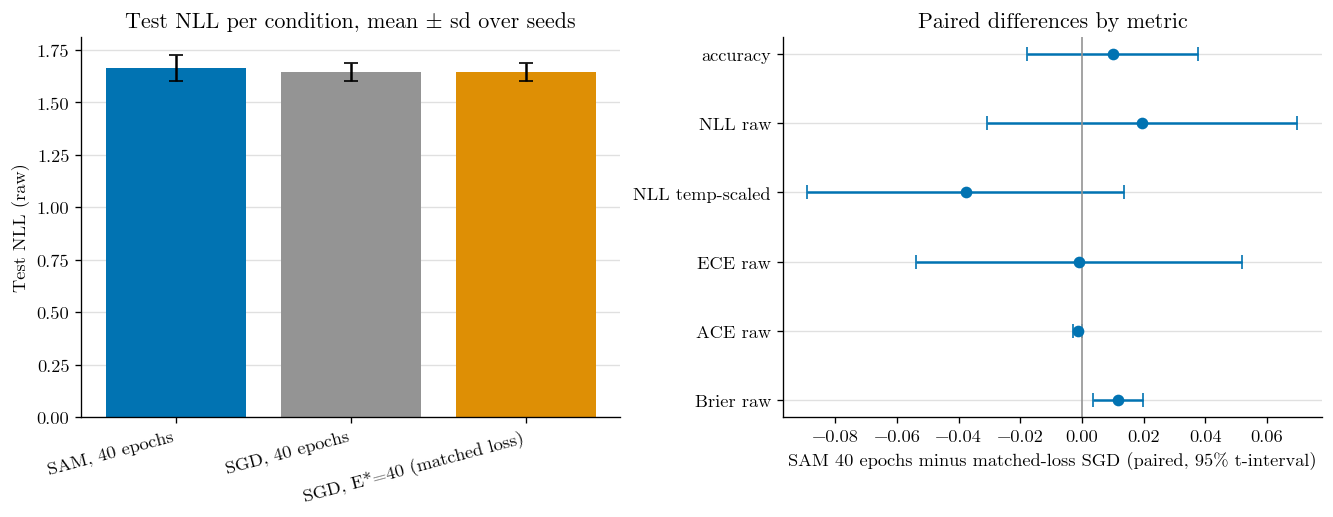

In [16]:
def load_run(name: str) -> dict:
    return json.loads((RUNS / f"{name}.json").read_text())


METRICS = {
    "accuracy": ("test_raw", "accuracy"),
    "NLL raw": ("test_raw", "nll"),
    "NLL temp-scaled": ("test_ts", "nll"),
    "ECE raw": ("test_raw", "ece"),
    "ACE raw": ("test_raw", "ace"),
    "Brier raw": ("test_raw", "brier"),
}
conditions = {
    f"SAM, {EPOCHS} epochs": [f"c1_sam_s{s}" for s in SEEDS_MAIN],
    f"SGD, {EPOCHS} epochs": [f"c2_sgd40_s{s}" for s in SEEDS_MAIN],
}
if E_STAR is not None:
    conditions[f"SGD, E*={E_STAR} (matched loss)"] = [f"c3_sgdE{E_STAR}_s{s}" for s in SEEDS_MAIN]

vals = {c: {m: np.array([load_run(n)["final"][b][k] for n in names]) for m, (b, k) in METRICS.items()}
        for c, names in conditions.items()}

print(f"Test metrics, mean ± sd over {len(SEEDS_MAIN)} seeds (EPOCHS={EPOCHS})")
for c in vals:
    print(c)
    for m in METRICS:
        v = vals[c][m]
        print(f"  {m:<16} {v.mean():.4f} ± {v.std(ddof=1):.4f}")

if E_STAR is not None:
    matched = f"SGD, E*={E_STAR} (matched loss)"
    diffs = {}
    for m in METRICS:
        d = vals[f"SAM, {EPOCHS} epochs"][m] - vals[matched][m]  # paired by seed
        half = stats.t.ppf(0.975, len(d) - 1) * d.std(ddof=1) / np.sqrt(len(d))
        diffs[m] = (d.mean(), d.mean() - half, d.mean() + half)
    print(f"\nPaired difference, SAM {EPOCHS} epochs minus matched-loss SGD (95% t-interval)")
    for m, (mu, lo, hi) in diffs.items():
        print(f"  {m:<16} {mu:+.4f}  [{lo:+.4f}, {hi:+.4f}]")

    names_c = list(vals)
    colours = [COLOURS["method"], COLOURS["baseline"], COLOURS["other_1"]][:len(names_c)]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    mu_nll = [vals[c]["NLL raw"].mean() for c in names_c]
    sd_nll = [vals[c]["NLL raw"].std(ddof=1) for c in names_c]
    axes[0].bar(range(len(names_c)), mu_nll, yerr=sd_nll, color=colours, capsize=4)
    axes[0].set_xticks(range(len(names_c)), names_c, rotation=15, ha="right")
    axes[0].set_ylabel("Test NLL (raw)")
    axes[0].set_title("Test NLL per condition, mean ± sd over seeds")

    labels = list(diffs)
    est = np.array([diffs[m][0] for m in labels])
    lo = np.array([diffs[m][1] for m in labels])
    hi = np.array([diffs[m][2] for m in labels])
    axes[1].errorbar(est, range(len(labels)), xerr=[est - lo, hi - est], fmt="o",
                     color=COLOURS["method"], capsize=4)
    axes[1].axvline(0, color=COLOURS["baseline"], linewidth=1)
    axes[1].set_yticks(range(len(labels)), labels)
    axes[1].invert_yaxis()
    axes[1].set_xlabel(f"SAM {EPOCHS} epochs minus matched-loss SGD (paired, 95% t-interval)")
    axes[1].set_title("Paired differences by metric")
    fig.savefig(FIGS / "demo_summary.png")
    plt.show()
else:
    print("Condition 3 infeasible: no matched-loss comparison was produced.")


## Interpreting the results

The printed differences and the figure show, for each metric, how far SAM after 40 epochs sits from SGD trained for the same training loss. The test NLL (raw and temperature-scaled), ECE, ACE and Brier score measure calibration and sharpness. Accuracy measures ranking. A difference whose 95% interval excludes zero is a candidate effect, but with only a few seeds the intervals are wide and the power is low.

In this run (40 epochs, five seeds, 20 test images), SAM's test accuracy is 0.48 against 0.47 for matched-loss SGD. The paired difference is +0.010 with a 95% interval of [-0.018, +0.038]. Raw NLL is higher for SAM (+0.020, [-0.031, +0.070]), temperature-scaled NLL is lower (-0.038, [-0.089, +0.014]), and raw ECE shows no difference (-0.001, [-0.054, +0.052]). The Brier score is worse for SAM (+0.012, [+0.004, +0.020]), the only interval that excludes zero, and no multiplicity correction is applied here.

Two points limit what these numbers mean. First, E* equals 40 in this run: the pilot found no shorter SGD run whose training loss matched SAM's, so condition 3 is the same as condition 2 and the comparison is SAM against 40-epoch SGD. Second, with 20 test images each seed moves accuracy in steps of 0.05, so the accuracy intervals are coarse. The paper's claim concerns the full Fashion-MNIST split with five paired seeds. This notebook does not test that claim: its effect sizes come from 20 test images per seed.
